# Ejercicio 8

## Contexto

Formas parte de un equipo que está preparando los datos de una futura herramienta de **mantenimiento predictivo**. Una fábrica utiliza tres máquinas industriales (M01, M02 y M03) y ha facilitado un histórico de medidas. Cada registro contiene las condiciones de funcionamiento y una columna que indica si **se observó una incidencia durante la hora siguiente**.

El responsable quiere saber **qué máquina necesita atención prioritaria, qué variables podrían ayudar a anticipar problemas y qué registros convendría revisar antes de entrenar un modelo de IA**. No te pide entrenar un modelo todavía.

Los datos se encuentran en el fichero **lecturas_maquinas.csv**

Explicación de las columnas:

| Columna | Significado |
|---|---|
| registro | Identificador único esperado de cada lectura |
| maquina | M01, M02 o M03 |
| turno | Turno de trabajo, de 1 a 4 |
| franja | Franja de observación, de 0 a 9 dentro de cada turno |
| carga_pct | Porcentaje de carga de la máquina |
| temperatura_c | Temperatura en °C |
| vibracion_mm_s | Vibración en mm/s |
| consumo_kwh | Consumo de energía de la franja |
| presion_bar | Presión en bares |
| incidencia_proxima_hora | 1 si se registró una incidencia en la siguiente hora; 0 en caso contrario |

**Advertencia:** son datos simulados de un histórico y pueden contener errores de calidad. La columna de incidencia describe lo ocurrido *después* de la lectura.

## Lo que tienes que hacer

Elabora un análisis que permita comunicar a mantenimiento:

1. ¿Hasta qué punto son fiables los datos recibidos para comenzar a analizarlos? ¿Qué decisiones has tomado ante los problemas que encuentres? NOTA: para borrar datos duplicados puedes usar el método drop_duplicates() y para borrar filas con columnas None puedes hacer uso de dropna().
2. ¿Cuál de las tres máquinas parece más preocupante? Explica en qué evidencias te basas y por qué no basta con elegir la máquina que tenga una medida máxima más alta. NOTA: sería bueno saber el valor medio de cada parámetro, cuántas incidencias se registan y el porcentaje de estas de cada máquina.
3. ¿Qué señales previas a una incidencia merece la pena investigar? ¿Qué relación observas entre las medidas disponibles y las incidencias registradas? NOTA: un diagrama de dispersión te puede ayudar a identificar patrones de comportamiento seleccionando adecuadamente los parámetros.
4. Selecciona **un conjunto reducido de lecturas que merecerían una revisión preventiva**, aunque todavía no haya ocurrido una incidencia. Explica tus criterios sin consultar la etiqueta de incidencia para decidir qué lecturas seleccionas. NOTA: elige unos criterios o valores a partir de los cuáles considerar que hay un funcionamiento anómalo.
5. Comprueba cuántas de las lecturas que marcaste como aviso acabaron teniendo una incidencia y cuántas no. ¿Es suficiente esta comprobación para asegurar que tu sistema anticipará averías futuras? NOTA: Compara los registros que tienen incidencia y cuáles marcaste tú como con incidencia. 

Elige **al menos dos representaciones gráficas diferentes** que aporten información útil al diagnóstico. No hay un único análisis correcto; se valorarán las decisiones y las conclusiones respaldadas por datos.

## Entrega

- Crea un archivo **analisis_maquinas.py** con **al menos tres funciones propias**: una para cargar o preparar datos, una para obtener resultados de un subconjunto y otra para seleccionar registros de interés mediante criterios definidos por ti. Puedes añadir más si lo necesitas.
- Crea un **actividad.ipynb** que **importe y utilice** esas funciones. No se considera válido copiar todas las funciones en las celdas del notebook sin importarlas desde el .py.
- En el notebook incluye el análisis, las gráficas y una conclusión final.
- Exporta **lecturas_revision.json** con las lecturas seleccionadas para revisión y guarda las gráficas en formato jpg.


Nº registros eliminados: 6
  maquina  registros  media_temperatura  media_vibracion  media_consumo  \
0     M01         39              71.82             3.84           7.73   
1     M02         39              79.86             5.06           7.68   
2     M03         38              68.93             3.53           7.34   

   media_presion  incidencias  porcentaje_incidencias  
0           7.41            8               20.512821  
1           7.15           15               38.461538  
2           7.35            6               15.789474  


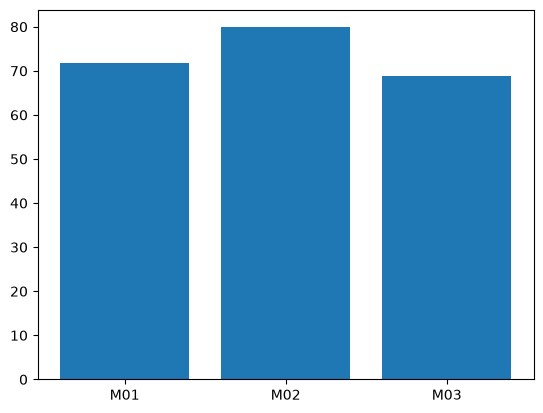

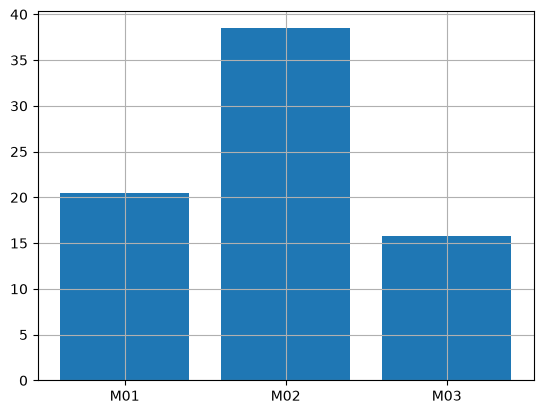

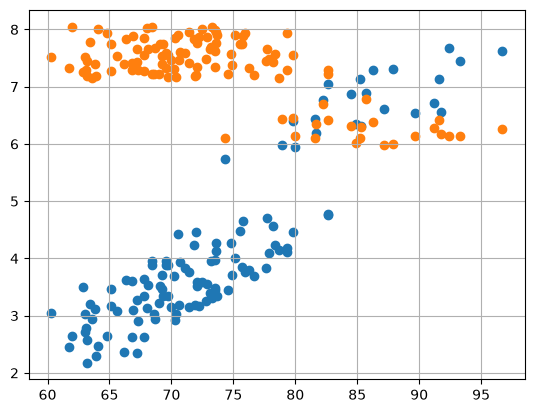

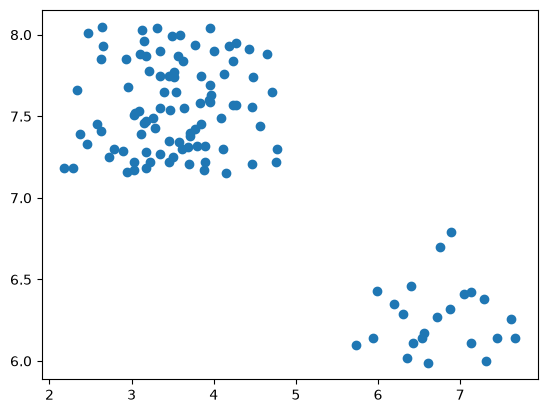

In [31]:
import analisis_maquinas as anma
import importlib
import pandas as pd
import matplotlib.pyplot as plt
importlib.reload(anma)

# Cargamos los datos
datos = anma.obtener_datos_csv("lecturas_maquinas.csv")

# Limpiamos la información recibida de nulos y duplicados
datos_depurados = anma.limpiar_nulos_duplicados(datos)

# Mostramos cómo de bueno eran los datos brutos tras el filtrado
print(f"Nº registros eliminados: {len(datos)-len(datos_depurados)}")

resumen = []
for maquina in ['M01','M02','M03']:
    resumen.append(anma.insertar_datos(datos_depurados,maquina))

dato_resumen = pd.DataFrame(resumen)
print(dato_resumen)

plt.bar(dato_resumen["maquina"],dato_resumen["media_temperatura"])
plt.savefig("grafica1.jpg")
plt.show()
# la máquina 2 se caliente más que el resto

plt.bar(dato_resumen["maquina"],dato_resumen["porcentaje_incidencias"])
plt.grid()
plt.savefig("grafica2.jpg")
plt.show()

plt.scatter(datos_depurados["temperatura_c"],datos_depurados["vibracion_mm_s"])
plt.scatter(datos_depurados["temperatura_c"],datos_depurados["presion_bar"])
plt.grid()
plt.savefig("grafica3.jpg")
plt.show()
plt.scatter(datos_depurados["vibracion_mm_s"],datos_depurados["presion_bar"])
plt.savefig("grafica4.jpg")
plt.show()

In [38]:
datos_filtrados = datos_depurados[(datos_depurados["temperatura_c"]>81)|(datos_depurados["vibracion_mm_s"]>6)|(datos_depurados["presion_bar"]<6.5)]
print(f"Total registros a revisar: {len(datos_filtrados)}")
datos_filtrados.to_json("lecturas_revision.json",indent=4,force_ascii=False,orient="records")

Total registros a revisar: 25


**Conclusiones**
Se observa que la máquina 2 tiene mayor temperatura y además un mayor número de incidencias.
Viendo las correlaciones, la dispersión de temperatura y vibración tiene relevancia para valores superiores a 81º o 6mms (también es notable que el valor de la presión decae para valores altos de temperatura y vibración, a partir de 6.5 bar empieza a decrecer con el aumento de estos)